# WP11 · B1 kimya modelini SHAP ile açıklamak

**Aşama 1: kayıtlı model, gerçek test ilaçları, yeniden eğitim yok.** Açıklama “model hangi sayısal girdiyi nasıl kullandı?” sorusuna yanıt verir; “ilaç neden yan etki yapar?” veya bireysel klinik risk sorusuna yanıt vermez. Unknown çiftler doğrulanmış biyolojik negatif değildir.

10 seçilmiş outer PT–B1 modeli açıklanır. Yöntem, background ve alfabetik örnekler açıklama hesabından önce `policy_v1.json` ve hash kaydıyla sabitlendi. Kodlar etiket değeri okumaz; var olan OOF skorları yalnız eşitlik kontrolünde kullanılır.

## 1. Exact linear SHAP: hangi çıktı ve hangi referans?

Altı girdi için `v(S)=mean_train f(x_S,B_notS)` tanımlanır. Kayıtlı doğrusal logitte `φ_i=w_i(x_i−mean_train_i)`, `base=b+w·mean_train` ve `base+Σφ=z` tamdır. Bu **interventional** oyun kimyasal bağımlılıklara koşullamaz. Kelime biyolojik müdahale/nedensellik iddiası değildir. [Resmî LinearExplainer belgesi](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html) bu formülü açıklar. SHAP paketi kurulu olmadığından formül doğrudan uygulanmış, seçilmiş her örnekte 64 koalisyon ile bağımsız doğrulanmıştır.

Katkı birimi **logit**tir. Sigmoid skoruna katkılar doğrudan eklenmez; `expit(base+Σφ)` mevcut observed-record skorunu verir. [Resmî lojistik regresyon örneği](https://shap.readthedocs.io/en/latest/example_notebooks/tabular_examples/linear_models/Sentiment%20Analysis%20with%20Logistic%20Regression.html) ölçek ayrımını gösterir.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP11/B1_SHAP_v1'
F=ROOT/'reports/figures/WP11/B1_SHAP_v1';F.mkdir(parents=True,exist_ok=True)
policy=json.loads((Q/'policy_v1.json').read_text(encoding='utf-8'))
summary=json.loads((Q/'analysis_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'yöntem':policy['method'],'ölçek':policy['output_scale'],'background':policy['background'],'ön_kayıt':policy['status']}]).T)
display(pd.DataFrame([summary['max_errors']]).T.rename(columns={0:'en_büyük_mutlak_fark'}))
coverage=pd.read_csv(Q/'coverage_summary.csv');display(coverage)


,0
yöntem,"exact interventional linear SHAP,closed form;not approximate KernelSHAP or correlation-dependent..."
ölçek,saved decision logit z=b+w*x of observed-record proxy;identity link
background,all and only exact saved model train_drug_ids;uniform row weights;existing standardized features...
ön_kayıt,FROZEN_BEFORE_EXPLANATIONS


,en_büyük_mutlak_fark
max_additivity_error,3.552714e-15
max_OOF_score_error,3.330669e-16
max_raw_unit_SHAP_error,1.776357e-15
max_order_error,4.440892e-16
max_repeat_error,0.000000e+00
max_LOO_conservation_error,5.329071e-15
max_mask_abs_SHAP,0.000000e+00


,context,protocol,outer_fold,background_train,test_inventory,test_explained,test_abstain,declared_PT,fitted_PT,NA_PT,explained_pairs,protocol_common_PT
0,primary_o01_final,primary,1,43,13,11,2,220,220,0,2420,201
1,primary_o02_final,primary,2,43,13,11,2,262,262,0,2882,201
2,primary_o03_final,primary,3,43,12,11,1,268,267,1,2937,201
3,primary_o04_final,primary,4,44,12,10,2,270,270,0,2700,201
4,primary_o05_final,primary,5,43,12,11,1,275,275,0,3025,201
5,stress_o01_final,stress,1,42,13,12,1,261,261,0,3132,186
6,stress_o02_final,stress,2,44,13,10,3,262,262,0,2620,186
7,stress_o03_final,stress,3,42,12,12,0,280,280,0,3360,186
8,stress_o04_final,stress,4,45,12,9,3,273,273,0,2457,186
9,stress_o05_final,stress,5,43,12,11,1,212,211,1,2321,186


**Yorum:** Model ağırlıkları ve scaler'lar değişmedi. Background yalnız uygun train ilaçlarıdır; her modelde 42–45 ilaç vardır. Hesaplanan 27.854 yerel model çıktısı ve 167.124 özellik katkısı yeni performans değerlendirmesi değildir. Toplamsallık farkı yaklaşık 3,6×10⁻¹⁵; kayıtlı OOF skor farkı 3,3×10⁻¹⁶'dır.

## 2. Hangi ilaç/PT için açıklama var?

protocol
primary    [DB01155, DB01165, DB00978, DB01044, DB06799, DB00798, DB01150, DB00578]
stress     [DB01165, DB00578, DB00798, DB01150, DB00978, DB01155, DB06799, DB01044]
Name: açıklanmayan_8_ilaç, dtype: object

,context,class_id,term,status,saved_fit_status,test_drugs_explained
592,primary_o03_final,C0027497,Nausea,NA_not_fitted,NA_single_proxy_outcome,0
2457,stress_o05_final,C0027497,Nausea,NA_not_fitted,NA_single_proxy_outcome,0


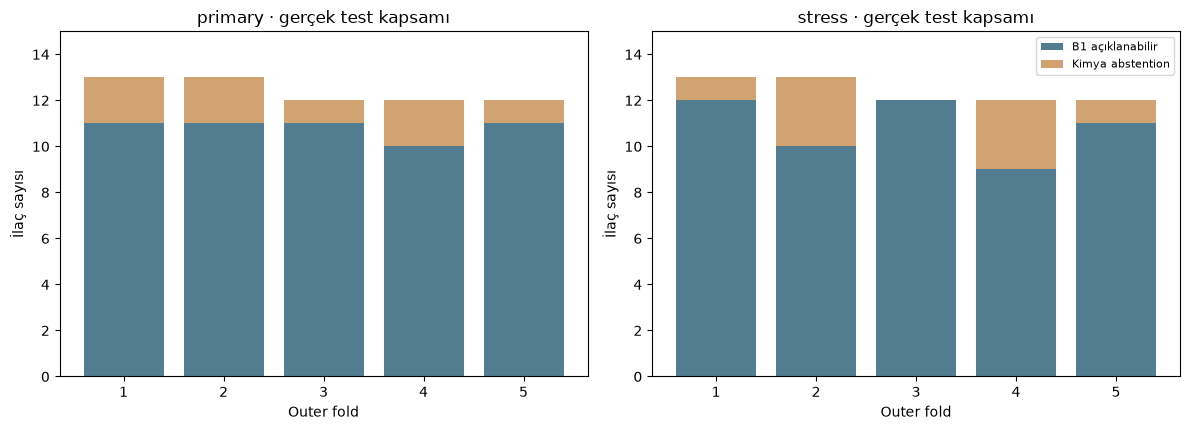

In [2]:

membership=pd.read_csv(Q/'background_test_membership.csv')
display(membership[membership.role.eq('TEST_ABSTAIN_QC')].assign(protocol=lambda x:x.context.str.split('_').str[0]).groupby('protocol').drug_id.agg(list).rename('açıklanmayan_8_ilaç'))
targets=pd.read_csv(Q/'target_coverage.csv');display(targets[targets.status.ne('explained')])
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
for ax,p in zip(axs,['primary','stress']):
    d=coverage[coverage.protocol.eq(p)]
    ax.bar(d.outer_fold,d.test_explained,label='B1 açıklanabilir',color='#527d91')
    ax.bar(d.outer_fold,d.test_abstain,bottom=d.test_explained,label='Kimya abstention',color='#d0a371')
    ax.set(title=p+' · gerçek test kapsamı',xlabel='Outer fold',ylabel='İlaç sayısı',xticks=range(1,6),ylim=(0,15))
axs[1].legend(fontsize=8);plt.tight_layout();plt.savefig(F/'01_explanation_scope.png',dpi=160);plt.show()


**Grafik 1 — Ne öğrendik?** 62 ilaç envanterde kalır; her protokolde 54 gerçek test ilacı açıklanır. Sekiz kimya-QC abstention için sıfır katkı veya sahte skor yazılmaz. Primary outer3 ve stress outer5'te birer declared PT için classifier fit edilmemiştir; bunlar NA kalır. PT sayısı foldda değişir, bütün 1.061 kaynak PT açıklanmış değildir.

## 3. Beş kimyasal alan ile availability maskesi

MW molekül ağırlığı, LogP lipofilisite betimi, HBD/HBA hidrojen bağı verici/alıcı sayısı, TPSA polar yüzey alanıdır. WP04'teki mevcut temiz sayılar kullanılır. B1 girdileri train-only standartlaştırılmıştır; SHAP'ın birimi ise logittir. Affine standartlaştırma altında ham birimler ile SHAP eşitliği ayrıca test edilmiştir.

,context,feature,n_train,mean_standardized,std_standardized_ddof0,min,max
0,primary_o01_final,chem__MW,43,-4.260158e-17,1.0,-1.030399,4.470053
1,primary_o01_final,chem__LogP,43,-5.163828e-18,1.0,-3.334101,2.246870
2,primary_o01_final,chem__HBD,43,1.097313e-17,1.0,-0.978886,3.915543
3,primary_o01_final,chem__HBA,43,9.682178e-17,1.0,-1.091835,3.718502
4,primary_o01_final,chem__TPSA,43,-2.004211e-16,1.0,-0.879134,4.075701
5,primary_o01_final,mask__chemistry,43,1.000000e+00,0.0,1.000000,1.000000


,protocol,feature,feature_type,mean_signed,mean_abs,n_drug_PT
0,primary,chem__HBA,chemistry,0.005297,0.149813,10854
1,primary,chem__HBD,chemistry,-0.036239,0.206057,10854
2,primary,chem__LogP,chemistry,0.021144,0.166537,10854
3,primary,chem__MW,chemistry,0.035937,0.168697,10854
4,primary,chem__TPSA,chemistry,-0.027190,0.172126,10854
5,primary,mask__chemistry,availability_mask,0.000000,0.000000,10854
6,stress,chem__HBA,chemistry,-0.006361,0.142032,10044
7,stress,chem__HBD,chemistry,0.008905,0.172390,10044
8,stress,chem__LogP,chemistry,-0.051728,0.300700,10044
9,stress,chem__MW,chemistry,0.029523,0.130361,10044


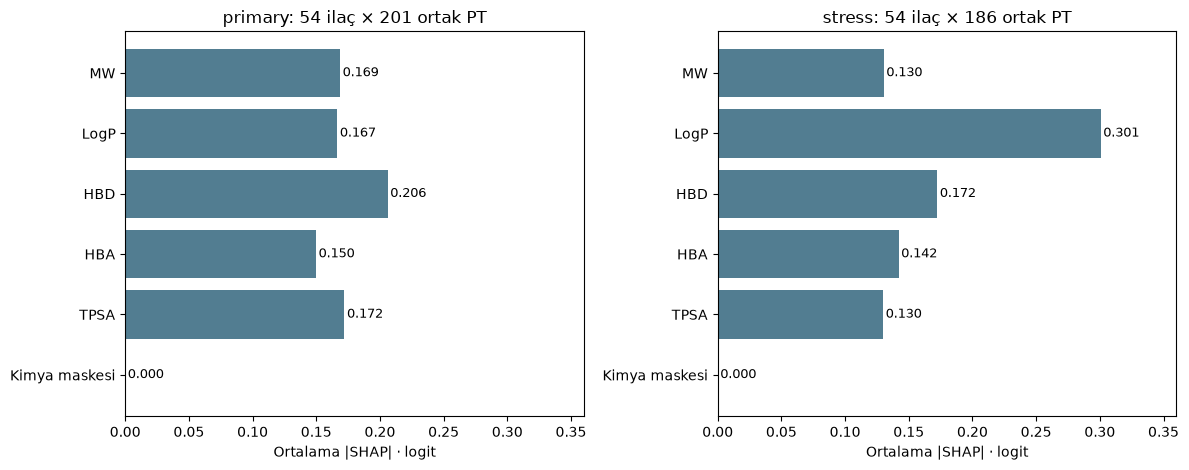

In [3]:

bg=pd.read_csv(Q/'background_summary.csv');display(bg[bg.context.eq('primary_o01_final')])
global_summary=pd.read_csv(Q/'global_common_summary.csv')
common=json.loads((Q/'common_PT_intersections.json').read_text(encoding='utf-8'))
features=policy['features'];labels=['MW','LogP','HBD','HBA','TPSA','Kimya maskesi']
display(global_summary)
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for ax,p in zip(axs,['primary','stress']):
    d=global_summary[global_summary.protocol.eq(p)].set_index('feature').loc[features]
    ax.barh(labels,d.mean_abs,color=['#527d91']*5+['#ba9470']);ax.invert_yaxis()
    ax.set(title=f'{p}: 54 ilaç × {len(common[p])} ortak PT',xlabel='Ortalama |SHAP| · logit')
    for i,v in enumerate(d.mean_abs):ax.text(v+.002,i,f'{v:.3f}',va='center',fontsize=9)
    ax.set_xlim(0,.36)
plt.tight_layout();plt.savefig(F/'02_global_common_PT_SHAP.png',dpi=160);plt.show()


**Grafik 2 — Ne öğrendik?** Primary beş-fold PT kesişimi 201, stres kesişimi 186'dır. Primary'de ortalama mutlak katkı HBD için 0,206; stres özetinde LogP için 0,301 logittir. Aynı biyolojik önem sırası elde edildiği iddia edilemez: hedef kesişimleri ve kayıtlı fold modelleri farklıdır. Bu betimsel ortak-kapsam özetidir; ilk/global esas tablo her model–PT için ayrı tutulur.

Maske tüm uygun train/test ilaçlarında 1 olduğu için referanstan farkı ve SHAP değeri sıfırdır. Kayıtlı maskenin katsayısı sıfır olmak zorunda değildir; sabit etkisi base'e dahildir. Bu, eksik kimya durumunun modelce öğrenildiği veya önemsiz olduğu anlamına gelmez.

## 4. Başarıya bakılmadan seçilmiş gerçek local açıklamalar

Her bağlamda alfabetik ilk iki uygun test ID'si ve ilk iki fit edilmiş CUI seçilmiştir. Aşağıdaki 40 örnek, etiket/skor büyüklüğü ya da doğru tahmin ölçütü kullanılmadan önceden donduruldu. Waterfall her protokolün outer1 ilk örneğidir.

,context,drug_id,drug_name,class_id,base,sum_phi,logit,proxy_score
0,primary_o01_final,DB00254,Doxycycline,C0000731,-1.046051,-0.085685,-1.131736,0.243841
1,primary_o01_final,DB00254,Doxycycline,C0000737,0.912119,-0.210158,0.701961,0.668622
2,primary_o01_final,DB00438,Ceftazidime,C0000731,-1.046051,-0.026620,-1.072670,0.254896
3,primary_o01_final,DB00438,Ceftazidime,C0000737,0.912119,-0.127103,0.785016,0.686760
4,primary_o02_final,DB00207,Azithromycin,C0000731,-0.830323,0.081570,-0.748753,0.321093
5,primary_o02_final,DB00207,Azithromycin,C0000737,1.060487,-0.006863,1.053623,0.741470
6,primary_o02_final,DB00415,Ampicillin,C0000731,-0.830323,0.041864,-0.788460,0.312500
7,primary_o02_final,DB00415,Ampicillin,C0000737,1.060487,0.098607,1.159094,0.761168
8,primary_o03_final,DB00199,Erythromycin,C0000731,-1.453477,0.589957,-0.863520,0.296604
9,primary_o03_final,DB00199,Erythromycin,C0000737,1.468857,1.760996,3.229853,0.961942


,raw_value,standardized_value,background_mean_standardized,coefficient,SHAP_logit,term
feature,,,,,,
chem__MW,444.4400,-0.103633,-6.325689e-17,0.050696,-0.005254,Abdominal distension
chem__LogP,-0.3476,-0.343312,1.549148e-17,0.124511,-0.042746,Abdominal distension
chem__HBD,6.0000,0.489443,-9.682178e-18,-0.079556,-0.038938,Abdominal distension
chem__HBA,9.0000,0.062646,7.616646e-17,0.093562,0.005861,Abdominal distension
chem__TPSA,181.6200,0.238629,-1.591105e-16,-0.019311,-0.004608,Abdominal distension
mask__chemistry,1.0000,1.000000,1.000000e+00,-0.523025,-0.000000,Abdominal distension


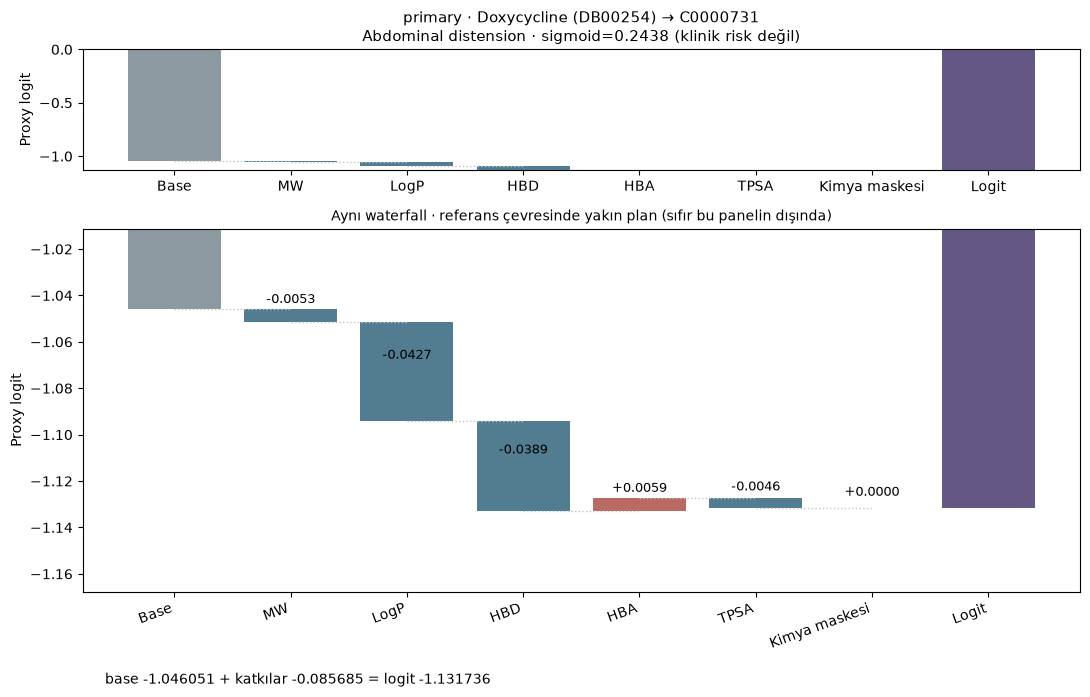

In [4]:

examples=pd.read_csv(Q/'examples_frozen_before_explanations.csv')
local=pd.read_csv(Q/'local_shap.csv');pairs=pd.read_csv(Q/'local_pair_outputs.csv')
example_local=pd.read_csv(Q/'example_local_shap.csv')
names=pd.read_csv(ROOT/'reports/qa/WP03/drug_pt_positives.csv',usecols=['id','name']).drop_duplicates().set_index('id')['name'].to_dict()
case_table=examples.merge(pairs,on=['context','protocol','drug_id','class_id'],validate='one_to_one')
case_table.insert(3,'drug_name',case_table.drug_id.map(names));display(case_table[['context','drug_id','drug_name','class_id','base','sum_phi','logit','proxy_score']])
def waterfall(protocol,filename):
    e=examples[examples.context.eq(protocol+'_o01_final')].iloc[0]
    vals=example_local[(example_local.context==e.context)&(example_local.drug_id==e.drug_id)&(example_local.class_id==e.class_id)].set_index('feature').loc[features]
    out=pairs[(pairs.context==e.context)&(pairs.drug_id==e.drug_id)&(pairs.class_id==e.class_id)].iloc[0]
    display(vals[['raw_value','standardized_value','background_mean_standardized','coefficient','SHAP_logit','term']])
    fig,axs=plt.subplots(2,1,figsize=(11,7),gridspec_kw={'height_ratios':[1,3]})
    contributions=vals.SHAP_logit.to_numpy();trajectory=np.r_[out.base,out.base+np.cumsum(contributions)]
    span=max(np.ptp(trajectory),.06);texts=['Base']+labels+['Logit']
    for ai,ax in enumerate(axs):
        position=out.base;ax.bar(0,position,color='#8c99a0')
        for i,value in enumerate(contributions,1):
            ax.bar(i,abs(value),bottom=min(position,position+value),color='#ba6a62' if value>0 else '#527d91')
            ax.plot([i-1,i],[position,position],color='#bfc4c7',linestyle=':',linewidth=1)
            if ai==1:ax.annotate(f'{0. if abs(value)<1e-12 else value:+.4f}',(i,position+value/2),xytext=(0,9),textcoords='offset points',ha='center',fontsize=9)
            position+=value
        ax.bar(7,out.logit,color='#655784');ax.set_xticks(range(8),texts,rotation=20 if ai else 0,ha='right' if ai else 'center')
        ax.set_ylabel('Proxy logit')
        if ai==0:ax.axhline(0,color='gray',linewidth=.7)
        else:ax.set_ylim(trajectory.min()-.4*span,trajectory.max()+.4*span);ax.set_title('Aynı waterfall · referans çevresinde yakın plan (sıfır bu panelin dışında)',fontsize=10)
    axs[0].set_title(f'{protocol} · {names.get(e.drug_id,e.drug_id)} ({e.drug_id}) → {e.class_id}\n{vals.term.iloc[0]} · sigmoid={out.proxy_score:.4f} (klinik risk değil)',fontsize=11)
    fig.text(.1,.015,f'base {out.base:.6f} + katkılar {out.sum_phi:+.6f} = logit {out.logit:.6f}',fontsize=10)
    plt.tight_layout(rect=(0,.04,1,1));plt.savefig(F/filename,dpi=160);plt.show()
waterfall('primary','03_local_primary_waterfall.png')


**Grafik 3 — Ne öğrendik?** Doxycycline (DB00254)–C0000731 örneğinde katkılar ilgili train referansına göre okunur. Mavi eksi katkı kimyasal alanın bu kayıtlı modelin logitini aşağı, kırmızı artı katkı yukarı taşıdığını gösterir. Bu mekanizma veya klinik koruyuculuk değildir. Base zaten train kayıt önseli, intercept ve sabit maskenin katkısını içerir. Düşük katkı modelin belirsizliğini ölçmez.

,raw_value,standardized_value,background_mean_standardized,coefficient,SHAP_logit,term
feature,,,,,,
chem__MW,250.2830,-0.811067,-2.564087e-16,0.007235,-0.005868,Abdominal distension
chem__LogP,0.8596,0.169665,-5.947623e-18,0.152090,0.025804,Abdominal distension
chem__HBD,2.0000,-0.526837,2.511219e-17,-0.030849,0.016252,Abdominal distension
chem__HBA,5.0000,-0.690333,-1.057355e-16,0.009831,-0.006787,Abdominal distension
chem__TPSA,97.9700,-0.623068,-1.189525e-16,-0.048806,0.030409,Abdominal distension
mask__chemistry,1.0000,1.000000,1.000000e+00,-0.439129,-0.000000,Abdominal distension


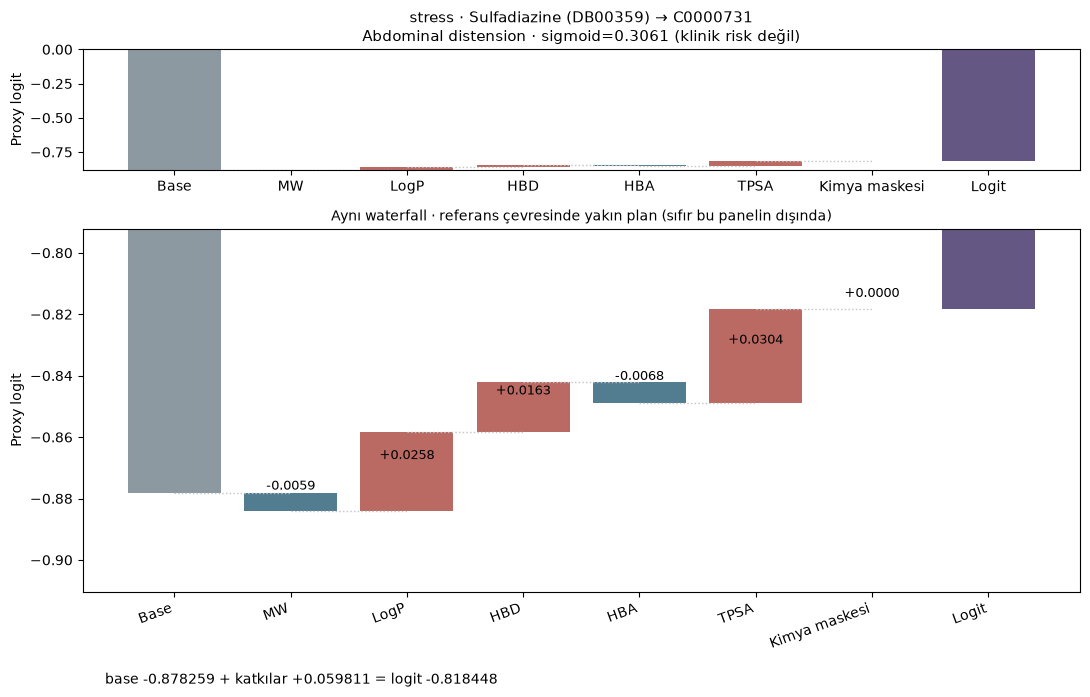

In [5]:

waterfall('stress','04_local_stress_waterfall.png')


**Grafik 4 — Ne öğrendik?** Stres outer1'in alfabetik ilk örneği ayrı model ve ayrı train referansı ile açıklanır. Buradaki katkı büyüklüklerini primary örneğiyle eşit biyolojik etki ölçeği sayamayız. İki grafik de gerçek kayıtlı test girdileri ve model ağırlıklarından hesaplanmıştır; temsili veri kullanılmamıştır.

## 5. Bir PT'yi foldlar arasında açıklamak

feature,chem__MW,chem__LogP,chem__HBD,chem__HBA,chem__TPSA,mask__chemistry
outer_fold,,,,,,
1,0.016941,0.096659,0.040708,0.062724,0.011507,0.0
2,0.008120,0.133369,0.005407,0.015363,0.045118,0.0
3,0.220818,0.337743,0.090940,0.070998,0.245550,0.0
4,0.004016,0.447012,0.239296,0.246628,0.317315,0.0
5,0.027328,0.038361,0.007032,0.022020,0.022462,0.0


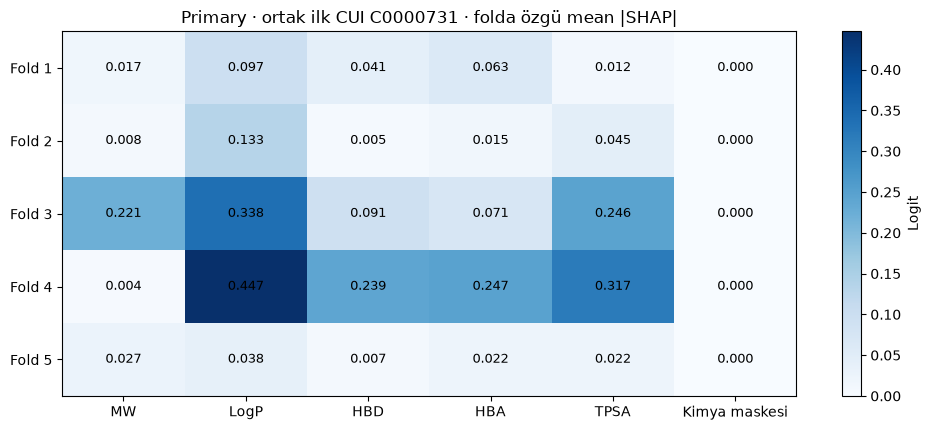

In [6]:

native=pd.read_csv(Q/'global_native_context_PT.csv')
cui=common['primary'][0]
d=native[native.protocol.eq('primary')&native.class_id.eq(cui)].pivot(index='outer_fold',columns='feature',values='mean_abs').loc[range(1,6),features]
display(d)
fig,ax=plt.subplots(figsize=(10,4.4));im=ax.imshow(d,aspect='auto',cmap='Blues',vmin=0)
ax.set_xticks(range(6),labels);ax.set_yticks(range(5),['Fold '+str(i) for i in range(1,6)])
for i in range(5):
    for j in range(6):ax.text(j,i,f'{d.iloc[i,j]:.3f}',ha='center',va='center',fontsize=9)
ax.set_title(f'Primary · ortak ilk CUI {cui} · folda özgü mean |SHAP|')
fig.colorbar(im,ax=ax,label='Logit');plt.tight_layout();plt.savefig(F/'05_native_PT_fold_heatmap.png',dpi=160);plt.show()


**Grafik 5 — Ne öğrendik?** Tek bir ortak CUI için bile katkılar train popülasyonu ve öğrenilmiş katsayılarla değişir. Her foldun ayrı tablosu korunmuştur. Eksik hedefler bu grafiğe sıfır olarak eklenmemiştir. Grafikteki fold farkı bir güven aralığı değildir.

## 6. Kararlılık: hesap aynı, referansa duyarlılık ayrı

,protocol,feature,max_shift,mean_shift,sign_flips,nonzero_comparisons,nonzero_sign_flip_fraction
0,primary,chem__HBA,0.108934,0.003120,0,602602,0.000000
1,primary,chem__HBD,0.167623,0.003459,262,568346,0.000461
2,primary,chem__LogP,0.157962,0.003700,1335,603152,0.002213
3,primary,chem__MW,0.168575,0.002634,6455,603152,0.010702
4,primary,chem__TPSA,0.134466,0.003272,3487,603152,0.005781
5,primary,mask__chemistry,0.000000,0.000000,0,0,NaN
6,stress,chem__HBA,0.095865,0.002891,0,597788,0.000000
7,stress,chem__HBD,0.155879,0.003160,2614,598312,0.004369
8,stress,chem__LogP,0.138042,0.003819,3107,598312,0.005193
9,stress,chem__MW,0.118837,0.002229,5146,598312,0.008601


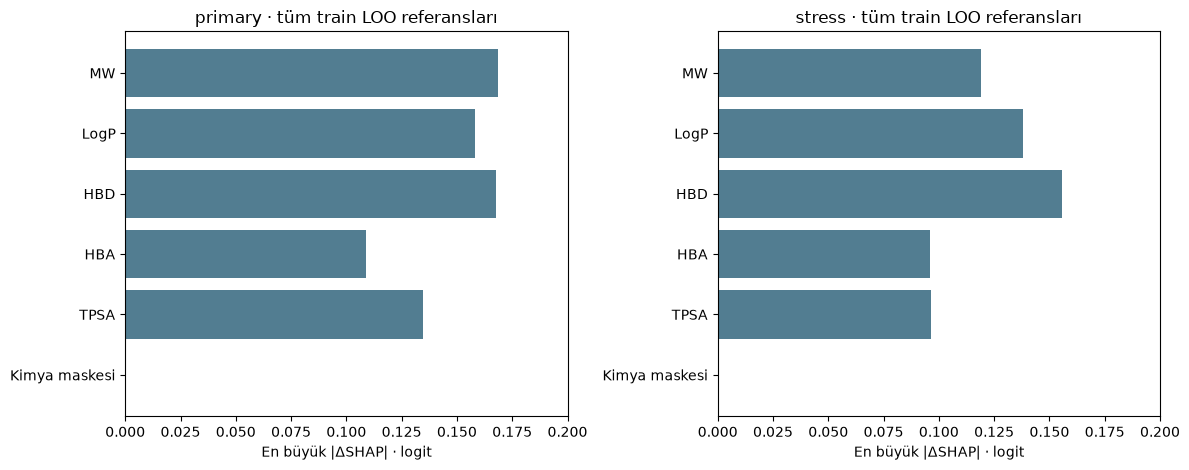

,context,max_additivity_error,max_OOF_score_error,max_raw_unit_SHAP_error,max_order_error,max_repeat_error,max_LOO_conservation_error,max_mask_abs_SHAP
0,primary_o01_final,8.881784e-16,1.665335e-16,2.220446e-16,1.110223e-16,0.0,1.332268e-15,0.0
1,primary_o02_final,4.440892e-16,1.665335e-16,2.220446e-16,2.775558e-17,0.0,8.881784e-16,0.0
2,primary_o03_final,3.552714e-15,3.330669e-16,8.881784e-16,1.110223e-16,0.0,5.329071e-15,0.0
3,primary_o04_final,1.776357e-15,2.498002e-16,8.881784e-16,4.440892e-16,0.0,3.552714e-15,0.0
4,primary_o05_final,2.220446e-16,2.220446e-16,2.220446e-16,2.775558e-17,0.0,6.661338e-16,0.0
5,stress_o01_final,2.220446e-16,1.942890e-16,1.110223e-16,1.387779e-17,0.0,4.440892e-16,0.0
6,stress_o02_final,2.220446e-16,2.220446e-16,5.551115e-17,5.551115e-17,0.0,4.440892e-16,0.0
7,stress_o03_final,1.776357e-15,2.775558e-16,1.776357e-15,1.110223e-16,0.0,5.329071e-15,0.0
8,stress_o04_final,1.776357e-15,2.220446e-16,4.440892e-16,5.551115e-17,0.0,2.220446e-15,0.0
9,stress_o05_final,8.881784e-16,2.220446e-16,4.440892e-16,2.220446e-16,0.0,1.776357e-15,0.0


,context,drug_id,class_id,coalitions,max_abs_SHAP_error,base_error
0,primary_o01_final,DB00254,C0000731,64,1.457168e-16,0.000000e+00
1,primary_o01_final,DB00254,C0000737,64,3.827234e-17,1.110223e-16
2,primary_o01_final,DB00438,C0000731,64,1.092876e-16,0.000000e+00
3,primary_o01_final,DB00438,C0000737,64,5.551115e-17,1.110223e-16
4,primary_o02_final,DB00207,C0000731,64,4.857226e-17,0.000000e+00
5,primary_o02_final,DB00207,C0000737,64,8.326673e-17,2.220446e-16
6,primary_o02_final,DB00415,C0000731,64,6.938894e-17,0.000000e+00
7,primary_o02_final,DB00415,C0000737,64,6.938894e-17,2.220446e-16
8,primary_o03_final,DB00199,C0000731,64,1.665335e-16,0.000000e+00
9,primary_o03_final,DB00199,C0000737,64,5.551115e-16,2.220446e-16


In [7]:

stability=pd.read_csv(Q/'stability_LOO.csv')
s=stability.groupby(['protocol','feature']).agg(max_shift=('max_abs_delta_SHAP','max'),mean_shift=('mean_abs_delta_SHAP','mean'),sign_flips=('nonzero_sign_flip_n','sum'),nonzero_comparisons=('nonzero_sign_comparisons','sum')).reset_index()
s['nonzero_sign_flip_fraction']=s.sign_flips/s.nonzero_comparisons.replace(0,np.nan)
display(s)
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for ax,p in zip(axs,['primary','stress']):
    d=s[s.protocol.eq(p)].set_index('feature').loc[features]
    ax.barh(labels,d.max_shift,color=['#527d91']*5+['#ba9470']);ax.invert_yaxis()
    ax.set(title=p+' · tüm train LOO referansları',xlabel='En büyük |ΔSHAP| · logit',xlim=(0,.2))
plt.tight_layout();plt.savefig(F/'06_background_LOO_sensitivity.png',dpi=160);plt.show()
display(pd.read_csv(Q/'consistency_checks.csv'))
display(pd.read_csv(Q/'enumeration_checks.csv'))


**Grafik 6 — Ne öğrendik?** Tek train-background ilacı çıkarıldığında bazı katkılar değişir; en büyük kayma primary'de yaklaşık 0,169, stres'te 0,156 logittir. Bazı küçük katkıların işareti değişir. Model tahmini sabit kalır: base ve SHAP kaymaları birbirini dengeler. Bu exhaustive background duyarlılığıdır; yeniden fit, bootstrap CI veya dış doğrulama değildir. Tekrar hesabı aynıdır, sıra değişimi sayısal yuvarlama düzeyindedir.

40 gerçek örnekte 64 koalisyon hesabı kapalı formu yaklaşık 8,9×10⁻¹⁶ en büyük farkla doğruladı. Ham/standartlaştırılmış alan açıklamaları da uyuştu. MW/TPSA/HBA gibi alanlar ilişkili olabilir; korelasyona koşullayan SHAP başka paylaştırmalar üretebilir. Bu aşamada sonuçlara göre alternatif açıklayıcı seçilmedi.

## 7. Testler, provenans ve koşullu graf yöntemi

In [8]:

print((Q/'tests_v1.txt').read_text(encoding='utf-8'))
display(pd.DataFrame([{'önceki_korunan_dosya':summary['preserved_prior_files'],'model_fit':summary['model_fit'],'protein_PPI_attribution':summary['graph_attribution'],'WP12':summary['WP12'],'test_etiketi_okundu':summary['test_outcomes_read']}]))
print('Graf yöntem önerisi:',ROOT/'docs/plan/WP11_A1P1_GRAPH_EXPLANATION_CONTRACT_v1.md')


test_01_policy_and_frozen_inputs (test_wp11_shap.TestWP11SHAP.test_01_policy_and_frozen_inputs) ... ok
test_02_all_prior_artifacts_unchanged (test_wp11_shap.TestWP11SHAP.test_02_all_prior_artifacts_unchanged) ... ok
test_03_known_linear_game (test_wp11_shap.TestWP11SHAP.test_03_known_linear_game) ... ok
test_04_all_40_real_coalition_checks (test_wp11_shap.TestWP11SHAP.test_04_all_40_real_coalition_checks) ... ok
test_05_all_saved_OOF_keys_and_scores (test_wp11_shap.TestWP11SHAP.test_05_all_saved_OOF_keys_and_scores) ... ok
test_06_additivity_all_real_outputs (test_wp11_shap.TestWP11SHAP.test_06_additivity_all_real_outputs) ... ok
test_07_train_only_exact_background (test_wp11_shap.TestWP11SHAP.test_07_train_only_exact_background) ... ok
test_08_affine_units_equivalence (test_wp11_shap.TestWP11SHAP.test_08_affine_units_equivalence) ... ok
test_09_repeat_and_background_query_target_orders (test_wp11_shap.TestWP11SHAP.test_09_repeat_and_background_query_target_orders) ... ok
test_10_heldo

,önceki_korunan_dosya,model_fit,protein_PPI_attribution,WP12,test_etiketi_okundu
0,3036,False,False,False,False


**Son sınır:** 18 test geçti. B0/B1/B2 ve WP09/WP10 ağırlıkları, sonuçları, splitleri ve QC kararları değişmedi. `local_shap.csv` tüm yerel katkıları, `global_native_context_PT.csv` model–PT özetlerini, `global_common_summary.csv` açık kesişim özetini saklar. Sekiz abstention ve fit edilmemiş PT'ler görünür kalır.

Kayıtlı WP10 A1P1 için ayrı yöntem sözleşmesi hazırlanmıştır: önerilen birincil işlem sabit-orijinal-derece mesaj maskesi; fiziksel kenar silme/yeniden normalizasyon ayrı duyarlılıktır. Dört protein rolü ayrı kalır, query readout ile paylaşılan train cache değişimleri ayrılır. **Bu notebook protein/kenar attribution hesaplamaz.** Grafik aşaması için onay beklenir. Yeni eğitim, WP12 veya klinik nedensellik/risk iddiası yoktur.